# L'Atelier Vert : analyse des ventes et des clients (2024-2025)

*Données fictives créées pour la démonstration. L'Atelier Vert est une boutique de plantes imaginaire (magasin, site web et marketplace).*

**Questions traitées**
1. Comment l'activité a-t-elle évolué entre 2024 et 2025 ?
2. Quelle est la saisonnalité de chaque catégorie ?
3. Quels produits portent le chiffre d'affaires ?
4. Quels clients faut-il fidéliser ou relancer en priorité (segmentation RFM) ?
5. Les nouveaux clients reviennent-ils (analyse de cohortes) ?

Outils : Python, pandas, matplotlib.

## 1. Chargement des données

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 10, "axes.titleweight": "bold"})
VERT, VERT_CLAIR = "#2E5E3E", "#A9C4A9"
FIG = Path("figures"); FIG.mkdir(exist_ok=True)

ventes = pd.read_csv("../data/ventes_atelier_vert_2024_2025.csv", sep=";", decimal=",", parse_dates=["Date"])
ventes["Année"] = ventes["Date"].dt.year
ventes["Mois"] = ventes["Date"].dt.month
print(f"{len(ventes):,} lignes · {ventes['ID_Commande'].nunique():,} commandes · {ventes['ID_Client'].nunique():,} clients")
ventes.head()

12,572 lignes · 6,897 commandes · 3,154 clients


,ID_Commande,Date,ID_Client,Région,Canal,ID_Produit,Produit,Catégorie,Quantité,Prix_Unitaire,Remise,Coût_Unitaire,CA_HT,Coût_Total,Marge,Année,Mois
0,CMD10001,2024-01-01,C00001,Auvergne-Rhône-Alpes,Magasin,P04,Sansevieria,Plantes d'intérieur,1,19.9,0.2,7.5,15.92,7.5,8.42,2024,1
1,CMD10002,2024-01-01,C00002,Pays de la Loire,Marketplace,P02,Ficus Lyrata,Plantes d'intérieur,1,39.9,0.0,16.5,39.90,16.5,23.40,2024,1
2,CMD10002,2024-01-01,C00002,Pays de la Loire,Marketplace,P20,Billes D'Argile 10 L,Terreaux & engrais,1,7.9,0.0,2.8,7.90,2.8,5.10,2024,1
3,CMD10003,2024-01-01,C00001,Auvergne-Rhône-Alpes,Magasin,P04,Sansevieria,Plantes d'intérieur,1,19.9,0.0,7.5,19.90,7.5,12.40,2024,1
4,CMD10003,2024-01-01,C00001,Auvergne-Rhône-Alpes,Magasin,P13,Pot Terre Cuite 20 Cm,Pots & cache-pots,2,9.9,0.0,3.5,19.80,7.0,12.80,2024,1


## 2. Indicateurs clés par année

In [2]:
kpi = ventes.groupby("Année").agg(CA=("CA_HT", "sum"), Marge=("Marge", "sum"),
                                  Commandes=("ID_Commande", "nunique"), Clients=("ID_Client", "nunique"))
kpi["Taux de marge"] = kpi["Marge"] / kpi["CA"]
kpi["Panier moyen"] = kpi["CA"] / kpi["Commandes"]
kpi["CA / client"] = kpi["CA"] / kpi["Clients"]
kpi.round(2)

,CA,Marge,Commandes,Clients,Taux de marge,Panier moyen,CA / client
Année,,,,,,,
2024,139392.22,85018.32,3286,1501,0.61,42.42,92.87
2025,151334.88,92461.38,3611,2076,0.61,41.91,72.90


Le chiffre d'affaires progresse d'environ **+8,6 %** avec un taux de marge stable autour de **61 %**. Le nombre de clients actifs augmente beaucoup plus vite que le CA, d'où une baisse du CA par client : la croissance vient surtout du recrutement, pas de la fidélisation.

## 3. Saisonnalité

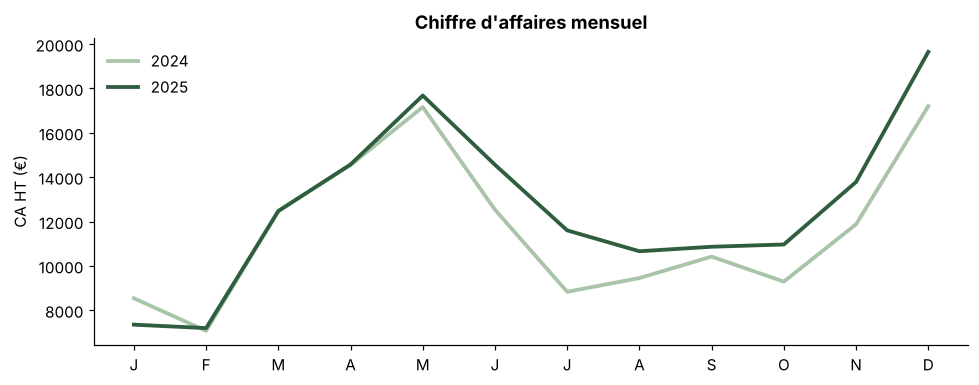

In [3]:
mensuel = ventes.pivot_table(index="Mois", columns="Année", values="CA_HT", aggfunc="sum")
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(mensuel.index, mensuel[2024], color=VERT_CLAIR, lw=2.5, label="2024")
ax.plot(mensuel.index, mensuel[2025], color=VERT, lw=2.5, label="2025")
ax.set_xticks(range(1, 13), ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"])
ax.set_ylabel("CA HT (€)"); ax.set_title("Chiffre d'affaires mensuel"); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "ca_mensuel.png"); plt.show()

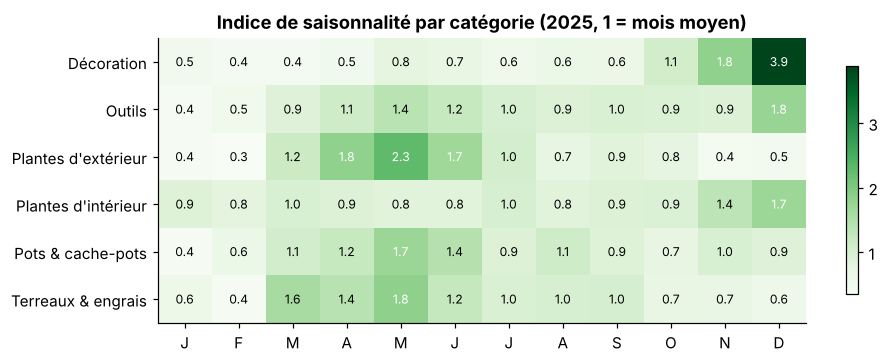

Mois,1,2,3,4,5,6,7,8,9,10,11,12
Catégorie,,,,,,,,,,,,
Décoration,0.50,0.44,0.44,0.51,0.79,0.71,0.56,0.64,0.62,1.09,1.84,3.88
Outils,0.40,0.54,0.88,1.11,1.39,1.22,0.99,0.90,0.97,0.94,0.91,1.76
Plantes d'extérieur,0.38,0.35,1.15,1.84,2.28,1.69,1.05,0.73,0.85,0.76,0.45,0.47
Plantes d'intérieur,0.89,0.80,0.98,0.93,0.84,0.83,0.99,0.84,0.92,0.93,1.35,1.71
Pots & cache-pots,0.39,0.63,1.07,1.22,1.73,1.44,0.92,1.11,0.89,0.74,0.97,0.88
Terreaux & engrais,0.60,0.38,1.60,1.40,1.84,1.24,0.96,0.99,1.02,0.71,0.69,0.57


In [4]:
cat_mois = ventes[ventes["Année"] == 2025].pivot_table(index="Catégorie", columns="Mois", values="CA_HT", aggfunc="sum")
indice = cat_mois.div(cat_mois.mean(axis=1), axis=0)      # 1 = mois moyen de la catégorie
fig, ax = plt.subplots(figsize=(9, 3.4))
im = ax.imshow(indice.values, cmap="Greens", aspect="auto")
ax.set_xticks(range(12), ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"])
ax.set_yticks(range(len(indice)), indice.index)
for i in range(indice.shape[0]):
    for j in range(12):
        v = indice.values[i, j]
        ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=8, color="white" if v > 1.6 else "black")
ax.set_title("Indice de saisonnalité par catégorie (2025, 1 = mois moyen)")
fig.colorbar(im, ax=ax, shrink=0.8); fig.tight_layout(); fig.savefig(FIG / "saisonnalite.png"); plt.show()
indice.round(2)

Deux pics très nets : **le printemps** (avril-mai), porté par les plantes d'extérieur, les terreaux et les pots, et **décembre**, porté par la décoration (près de 4 fois son mois moyen) et les plantes d'intérieur offertes en cadeau. Les stocks et les campagnes marketing doivent être calés sur ces deux fenêtres.

## 4. Concentration du chiffre d'affaires par produit

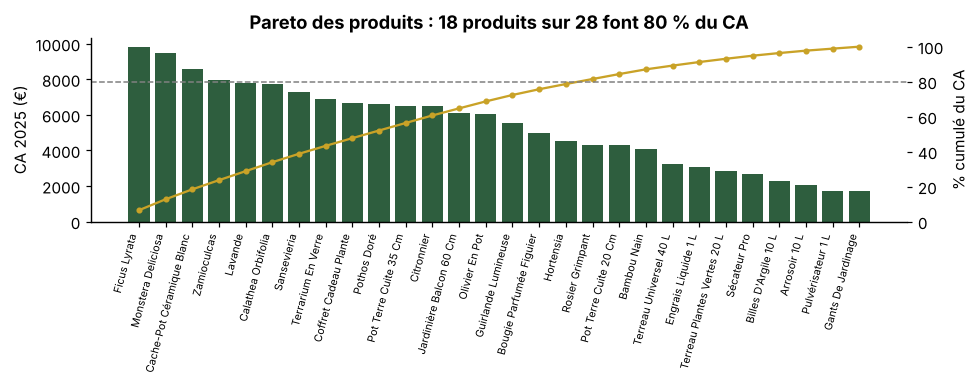

18 produits (64% du catalogue) réalisent 80 % du chiffre d'affaires 2025.


In [5]:
prod = ventes[ventes["Année"] == 2025].groupby("Produit")["CA_HT"].sum().sort_values(ascending=False)
part_cumulee = prod.cumsum() / prod.sum()
n80 = int((part_cumulee < 0.8).sum() + 1)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(range(len(prod)), prod.values, color=VERT)
ax2 = ax.twinx(); ax2.plot(range(len(prod)), part_cumulee.values * 100, color="#C9A227", marker="o", ms=3)
ax2.axhline(80, ls="--", color="grey", lw=1); ax2.set_ylim(0, 105); ax2.set_ylabel("% cumulé du CA")
ax.set_xticks(range(len(prod)), prod.index, rotation=75, ha="right", fontsize=7); ax.set_ylabel("CA 2025 (€)")
ax.set_title(f"Pareto des produits : {n80} produits sur {len(prod)} font 80 % du CA")
fig.tight_layout(); fig.savefig(FIG / "pareto_produits.png"); plt.show()
print(f"{n80} produits ({n80 / len(prod):.0%} du catalogue) réalisent 80 % du chiffre d'affaires 2025.")

Le catalogue est assez équilibré : il faut près des deux tiers des références pour atteindre 80 % du CA. Aucune référence n'est critique à elle seule, mais les dernières du classement pourraient être revues.

## 5. Segmentation RFM des clients

Chaque client reçoit un score de 1 à 5 sur trois critères, calculés au 31/12/2025 :
- **R**écence : nombre de jours depuis le dernier achat ;
- **F**réquence : nombre de commandes ;
- **M**ontant : chiffre d'affaires total.

Les combinaisons de scores R et F définissent six segments.

In [6]:
date_ref = ventes["Date"].max() + pd.Timedelta(days=1)
cmd = ventes.groupby(["ID_Client", "ID_Commande"]).agg(Date=("Date", "first"), CA=("CA_HT", "sum")).reset_index()
rfm = cmd.groupby("ID_Client").agg(Récence=("Date", lambda d: (date_ref - d.max()).days),
                                   Fréquence=("ID_Commande", "count"), Montant=("CA", "sum"))
# Scores de 1 à 5 (5 = meilleur), calculés sur les rangs pour gérer les ex æquo
rfm["R"] = pd.qcut(rfm["Récence"].rank(method="first", ascending=False), 5, labels=range(1, 6)).astype(int)
rfm["F"] = pd.qcut(rfm["Fréquence"].rank(method="first"), 5, labels=range(1, 6)).astype(int)
rfm["M"] = pd.qcut(rfm["Montant"].rank(method="first"), 5, labels=range(1, 6)).astype(int)

def segment(r):
    if r.R >= 4 and r.F >= 4: return "Champions"
    if r.R >= 3 and r.F >= 3: return "Fidèles"
    if r.R >= 4 and r.F <= 2: return "Nouveaux / récents"
    if r.R <= 2 and r.F >= 3: return "À risque"
    if r.R <= 2 and r.F <= 2: return "Perdus"
    return "À développer"

rfm["Segment"] = rfm.apply(segment, axis=1)
seg = rfm.groupby("Segment").agg(Clients=("Montant", "size"), CA=("Montant", "sum"),
                                 Récence_moy=("Récence", "mean"), Commandes_moy=("Fréquence", "mean"))
seg["Part clients"] = seg["Clients"] / seg["Clients"].sum()
seg["Part CA"] = seg["CA"] / seg["CA"].sum()
seg = seg.sort_values("CA", ascending=False)
seg.round(2)

,Clients,CA,Récence_moy,Commandes_moy,Part clients,Part CA
Segment,,,,,,
À risque,568,90569.71,474.43,3.74,0.18,0.31
Champions,612,84917.10,75.41,3.34,0.19,0.29
Fidèles,712,62126.20,131.19,2.06,0.23,0.21
Perdus,694,28606.14,496.42,1.00,0.22,0.10
À développer,323,13486.80,243.88,1.00,0.10,0.05
Nouveaux / récents,245,11021.15,148.77,1.00,0.08,0.04


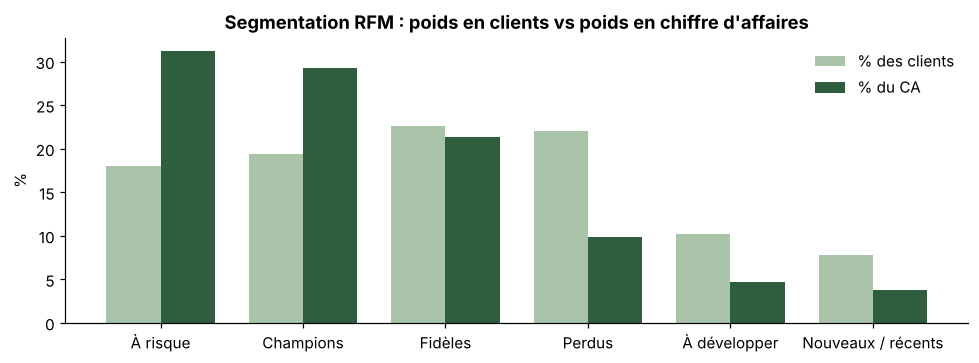

In [7]:
fig, ax = plt.subplots(figsize=(9, 3.4))
x = np.arange(len(seg)); w = 0.38
ax.bar(x - w / 2, seg["Part clients"] * 100, w, color=VERT_CLAIR, label="% des clients")
ax.bar(x + w / 2, seg["Part CA"] * 100, w, color=VERT, label="% du CA")
ax.set_xticks(x, seg.index); ax.set_ylabel("%"); ax.legend(frameon=False)
ax.set_title("Segmentation RFM : poids en clients vs poids en chiffre d'affaires")
fig.tight_layout(); fig.savefig(FIG / "segments_rfm.png"); plt.show()

**Point d'attention majeur : le segment « À risque ».** Ces clients ont beaucoup acheté par le passé (panier cumulé le plus élevé, environ 160 €) mais ne sont pas revenus récemment. Ils représentent environ **18 % des clients mais 31 % du CA** des deux années. Une campagne de relance ciblée (offre personnalisée, rappel d'entretien des plantes achetées) est l'action la plus rentable à court terme.

## 6. Rétention par cohorte

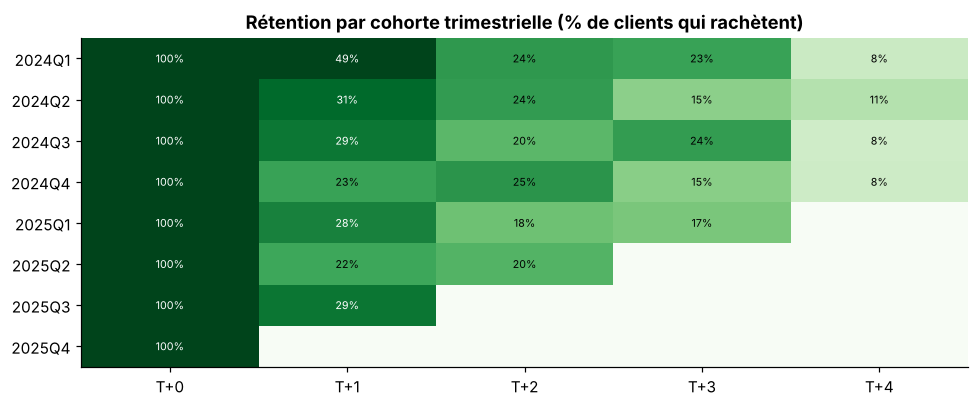

Taux moyen de rachat au trimestre suivant : 30%


In [8]:
premier = cmd.groupby("ID_Client")["Date"].min().dt.to_period("Q").rename("Cohorte")
c = cmd.join(premier, on="ID_Client")
c["Trimestre"] = c["Date"].dt.to_period("Q")
c["Ecart"] = (c["Trimestre"] - c["Cohorte"]).apply(lambda p: p.n)
taille = c.groupby("Cohorte")["ID_Client"].nunique()
retention = c.groupby(["Cohorte", "Ecart"])["ID_Client"].nunique().unstack(fill_value=0).div(taille, axis=0)
retention.index = retention.index.astype(str)
fig, ax = plt.subplots(figsize=(9, 3.8))
vals = retention.where(retention > 0).values
im = ax.imshow(np.where(np.isnan(vals), 0, vals), cmap="Greens", aspect="auto", vmax=0.35)
for i in range(vals.shape[0]):
    for j in range(vals.shape[1]):
        if not np.isnan(vals[i, j]):
            ax.text(j, i, f"{vals[i, j]:.0%}", ha="center", va="center", fontsize=7,
                    color="white" if vals[i, j] > 0.27 else "black")
ax.set_xticks(range(retention.shape[1]), [f"T+{k}" for k in retention.columns])
ax.set_yticks(range(len(retention)), retention.index)
ax.set_title("Rétention par cohorte trimestrielle (% de clients qui rachètent)")
fig.tight_layout(); fig.savefig(FIG / "cohortes.png"); plt.show()
print("Taux moyen de rachat au trimestre suivant :", f"{retention[1].iloc[:-1].mean():.0%}")

En moyenne, **environ 30 % des nouveaux clients rachètent le trimestre suivant**, puis la rétention se stabilise autour de 15 à 25 %. La cohorte du 1er trimestre 2024 fait exception (près de 50 % au trimestre suivant), sans doute parce qu'elle enchaîne directement sur la saison de printemps.

## 7. Synthèse et recommandations

| Constat | Recommandation |
|---|---|
| Croissance tirée par le recrutement, CA par client en baisse | Programme de fidélité ou abonnement « entretien » pour augmenter la fréquence |
| Clients « À risque » : 18 % des clients, 31 % du CA | Campagne de relance personnalisée en priorité |
| Deux pics : printemps (extérieur) et décembre (décoration) | Anticiper stocks et campagnes 6 à 8 semaines avant chaque pic |
| Faible rachat après le premier achat (≈ 30 %) | Séquence d'e-mails post-achat (conseils, offre de 2e commande) |

*Analyse réalisée sur des données fictives, à titre de démonstration.*